<a href="https://colab.research.google.com/github/laboratoriodecodigos/Colab-Python/blob/main/huggingface_transformers_visual.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🤗 Hugging Face Transformers: laboratorio visual
**Canal: Laboratorio de Códigos**

Qué vamos a hacer, todo con `pipeline()`:
1. 📦 Instalar y configurar
2. 💬 Texto: sentimiento en español + generación de texto
3. 🖼️ Visión: clasificación, CLIP (zero-shot), detección de objetos, segmentación y profundidad
4. 🎬 Remate: panel final 2x2 listo para pantalla de TikTok

📍 Repositorio: https://github.com/huggingface/transformers
🧠 Modelos: https://huggingface.co/models

⚠️ Activa GPU: *Entorno de ejecución → Cambiar tipo de entorno → T4 GPU*

## 1️⃣ Instalación

In [3]:
!pip install -q -U transformers accelerate pillow matplotlib requests

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
gradio 6.31.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.


## 2️⃣ Configuración

In [4]:
import requests
import numpy as np
import torch
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
import transformers
from transformers import pipeline

print("Transformers versión:", transformers.__version__)

# Token opcional (solo para modelos privados o para mejores límites de descarga).
# 1) Crea el token en https://huggingface.co/settings/tokens
# 2) Guárdalo en los Secretos de Colab (icono 🔑) con el nombre HF_TOKEN
try:
    from google.colab import userdata
    from huggingface_hub import login
    login(userdata.get("HF_TOKEN"))
    print("Token configurado ✅")
except Exception:
    print("Sin token: perfecto para modelos públicos 👍")

device = 0 if torch.cuda.is_available() else -1
print("GPU activa ✅" if device == 0 else "Usando CPU 🐢 (activa la GPU para ir más rápido)")

plt.rcParams["figure.dpi"] = 110
colores = plt.cm.tab20.colors

Transformers versión: 5.22.2
Sin token: perfecto para modelos públicos 👍
GPU activa ✅


### 🧰 Funciones de ayuda

In [5]:
def cargar_imagen(url):
    r = requests.get(url, stream=True, headers={"User-Agent": "Mozilla/5.0"})
    return Image.open(r.raw).convert("RGB")


def grafica_barras(etiquetas, valores, titulo, color="#7C4DFF"):
    fig, ax = plt.subplots(figsize=(8, 0.6 * len(etiquetas) + 1.5))
    barras = ax.barh(etiquetas[::-1], valores[::-1], color=color)
    ax.set_xlim(0, 1)
    ax.set_title(titulo, fontsize=15, weight="bold")
    for b, v in zip(barras, valores[::-1]):
        ax.text(min(v + 0.02, 0.85), b.get_y() + b.get_height() / 2,
                f"{v:.0%}", va="center", fontsize=12, weight="bold")
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    plt.show()


def dibujar_cajas(ax, img, resultados):
    ax.imshow(img)
    for i, r in enumerate(resultados):
        b = r["box"]
        c = colores[i % 20]
        ax.add_patch(patches.Rectangle(
            (b["xmin"], b["ymin"]), b["xmax"] - b["xmin"], b["ymax"] - b["ymin"],
            linewidth=4, edgecolor=c, facecolor="none"))
        ax.text(b["xmin"], max(b["ymin"] - 6, 12), f'{r["label"]} {r["score"]:.0%}',
                color="white", fontsize=12, weight="bold",
                bbox=dict(facecolor=c, alpha=0.9, pad=2))
    ax.axis("off")


def superponer_segmentos(img, segmentos):
    base = np.array(img).astype(float)
    leyenda = []
    for i, s in enumerate(segmentos):
        m = np.array(s["mask"]) > 0
        c = np.array(colores[i % 20][:3]) * 255
        base[m] = base[m] * 0.45 + c * 0.55
        leyenda.append(patches.Patch(color=colores[i % 20], label=s["label"]))
    return base.astype("uint8"), leyenda

## 🖼️ Imágenes de prueba

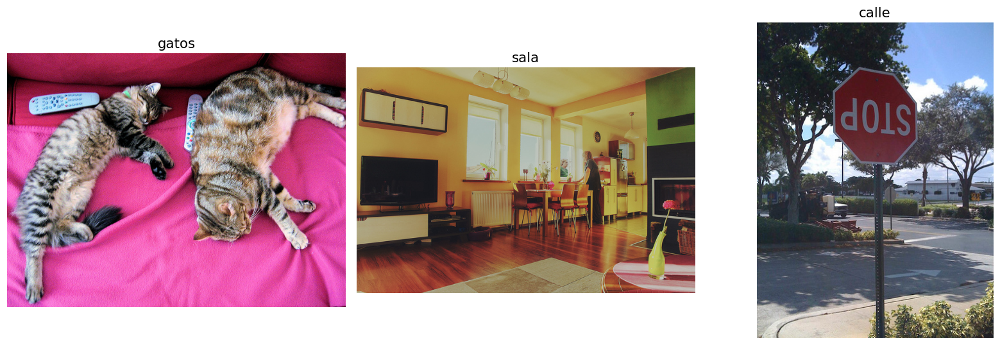

In [6]:
urls = {
    "gatos":  "http://images.cocodataset.org/val2017/000000039769.jpg",
    "sala":   "http://images.cocodataset.org/val2017/000000000139.jpg",
    "calle":  "http://images.cocodataset.org/val2017/000000000724.jpg",
}
imagenes = {nombre: cargar_imagen(u) for nombre, u in urls.items()}

fig, ejes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (nombre, im) in zip(ejes, imagenes.items()):
    ax.imshow(im); ax.set_title(nombre, fontsize=14); ax.axis("off")
plt.tight_layout(); plt.show()

**¿Quieres usar tu propia foto?** Ejecuta la siguiente celda, sube una imagen y se añadirá como `"mi_foto"`.

In [23]:
# OPCIONAL: sube tu propia imagen
from google.colab import files
import io

subida = files.upload()
if subida:
    nombre_archivo = list(subida.keys())[0]
    imagenes["mi_foto"] = Image.open(io.BytesIO(subida[nombre_archivo])).convert("RGB")
    print("Imagen añadida como 'mi_foto' ✅")

KeyboardInterrupt: 

## 3️⃣ Texto 💬

### Análisis de sentimiento en español (1 línea de magia)

config.json:   0%|          | 0.00/953 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  669MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/39.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/872k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

 5 stars (61%)  ←  Este canal me está cambiando la vida, qué gran explicación
 3 stars (68%)  ←  El tutorial estaba bien, pero me faltó un poco de detalle.
  1 star (80%)  ←  No me funcionó nada y perdí toda la tarde.


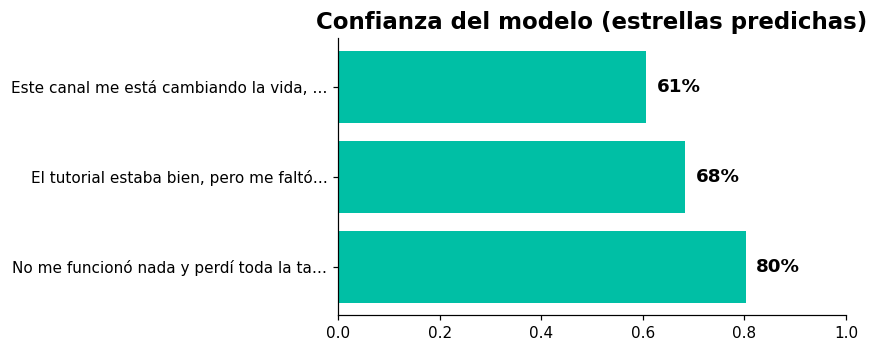

In [7]:
sentimiento = pipeline(
    "sentiment-analysis",
    model="nlptown/bert-base-multilingual-uncased-sentiment",
    device=device,
)

frases = [
    "Este canal me está cambiando la vida, qué gran explicación",
    "El tutorial estaba bien, pero me faltó un poco de detalle.",
    "No me funcionó nada y perdí toda la tarde.",
]

res = sentimiento(frases)
etiquetas = [f[:38] + "…" for f in frases]
valores = [r["score"] for r in res]
for f, r in zip(frases, res):
    print(f"{r['label']:>8} ({r['score']:.0%})  ←  {f}")

grafica_barras(etiquetas, valores, "Confianza del modelo (estrellas predichas)", "#00BFA5")

### Generación de texto con un LLM pequeño

In [11]:
generador = pipeline(
    "text-generation",
    model="Qwen/Qwen2.5-0.5B-Instruct",
    device=device,
)

mensajes = [{"role": "user",
             "content": "Explica en 3 frases qué es Hugging Face Transformers"}]
salida = generador(mensajes, max_new_tokens=250)
print(salida[0]["generated_text"][-1]["content"])

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Hugging Face Transformers es una biblioteca de modelos preentrenados para la generación de texto basada en el modelo de LLaMA (Large Language Model for AI). Es un conjunto completo de funciones y características que facilitan la creación de modelos de lenguaje natural, incluyendo:

1. **Generación de texto**: Utiliza el modelo LLaMA para generar texto aleatorio o realista.
2. **Modelo de entrenamiento**: Proporciona un entorno de entrenamiento para mejorar el rendimiento del modelo de generación.
3. **Estructura de datos**: Ofrece herramientas para manejar, procesar y manipular los datos de entrada y salida.

Esta biblioteca es fundamental para desarrolladores de aplicaciones de inteligencia artificial y aprendizaje profundo, ya que ofrece un alto nivel de eficiencia y flexibilidad para la generación de texto.


## 4️⃣ Visión 👁️

### Clasificación de imágenes: top 5

config.json:   0%|          | 0.00/69.7k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

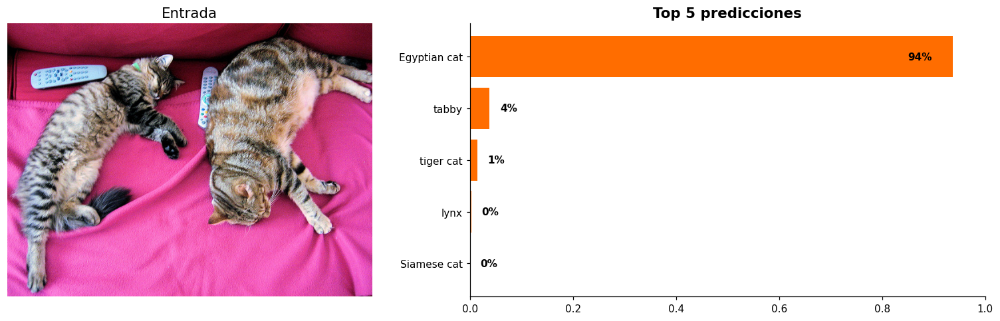

In [ ]:
clasificador = pipeline("image-classification", model="google/vit-base-patch16-224", device=device, top_k=5)

img = imagenes["gatos"]
res = clasificador(img)

fig, ejes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [1, 1.3]})
ejes[0].imshow(img); ejes[0].axis("off"); ejes[0].set_title("Entrada", fontsize=14)
etq = [r["label"].split(",")[0] for r in res][::-1]
val = [r["score"] for r in res][::-1]
barras = ejes[1].barh(etq, val, color="#FF6D00")
ejes[1].set_xlim(0, 1); ejes[1].set_title("Top 5 predicciones", fontsize=14, weight="bold")
for b, v in zip(barras, val):
    ejes[1].text(min(v + 0.02, 0.85), b.get_y() + b.get_height() / 2, f"{v:.0%}", va="center", weight="bold")
ejes[1].spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

### CLIP: clasificación *zero-shot* (tú inventas las etiquetas)

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

... (2 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

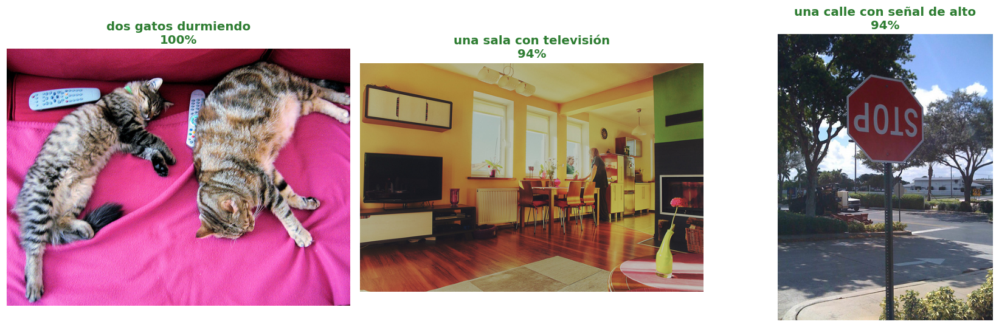

In [ ]:
clip = pipeline("zero-shot-image-classification", model="openai/clip-vit-base-patch32", device=device)

etiquetas_clip = ["dos gatos durmiendo", "un perro corriendo", "una sala con televisión",
                  "una calle con señal de alto", "un plato de comida"]

fig, ejes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (nombre, im) in zip(ejes, imagenes.items()):
    r = clip(im, candidate_labels=etiquetas_clip)[0]
    ax.imshow(im); ax.axis("off")
    ax.set_title(f"{r['label']}\n{r['score']:.0%}", fontsize=13, weight="bold", color="#2E7D32")
plt.tight_layout(); plt.show()

### Detección de objetos con cajas de colores

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

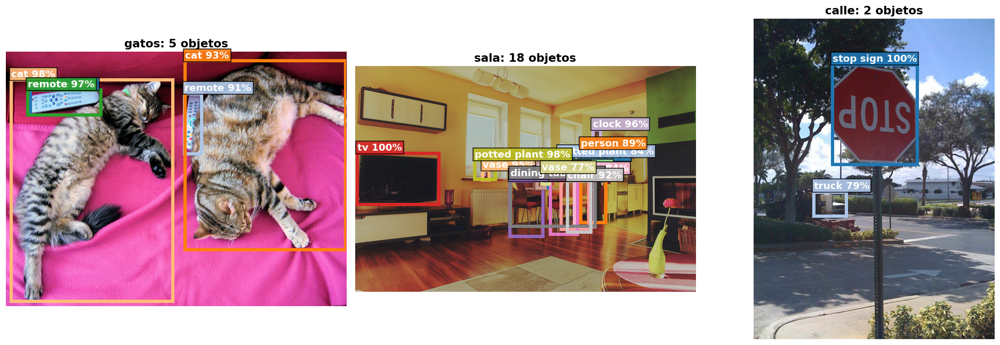

In [18]:
detector = pipeline("object-detection", model="hustvl/yolos-tiny", device=device)

fig, ejes = plt.subplots(1, 3, figsize=(18, 6))
for ax, (nombre, im) in zip(ejes, imagenes.items()):
    res = detector(im, threshold=0.7)
    dibujar_cajas(ax, im, res)
    ax.set_title(f"{nombre}: {len(res)} objetos", fontsize=14, weight="bold")
plt.tight_layout(); plt.show()

### Segmentación: la IA pinta cada región

config.json:   0%|          | 0.00/6.88k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 15.0MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/271 [00:00<?, ?B/s]

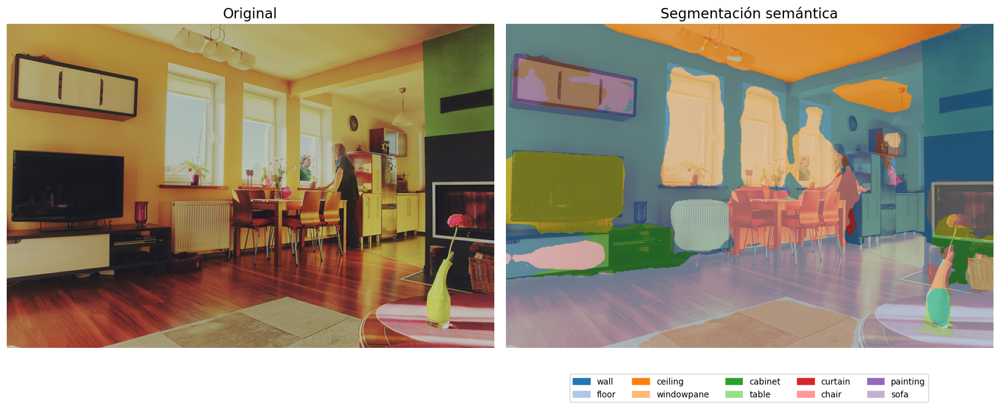

In [19]:
segmentador = pipeline("image-segmentation", model="nvidia/segformer-b0-finetuned-ade-512-512", device=device)

img = imagenes["sala"]
segmentos = segmentador(img)
superpuesta, leyenda = superponer_segmentos(img, segmentos)

fig, ejes = plt.subplots(1, 2, figsize=(15, 6))
ejes[0].imshow(img); ejes[0].set_title("Original", fontsize=15); ejes[0].axis("off")
ejes[1].imshow(superpuesta); ejes[1].set_title("Segmentación semántica", fontsize=15); ejes[1].axis("off")
ejes[1].legend(handles=leyenda[:10], loc="lower center", bbox_to_anchor=(0.5, -0.18), ncol=5, fontsize=9)
plt.tight_layout(); plt.show()

### Profundidad: qué está cerca y qué está lejos

Loading weights:   0%|          | 0/287 [00:00<?, ?it/s]

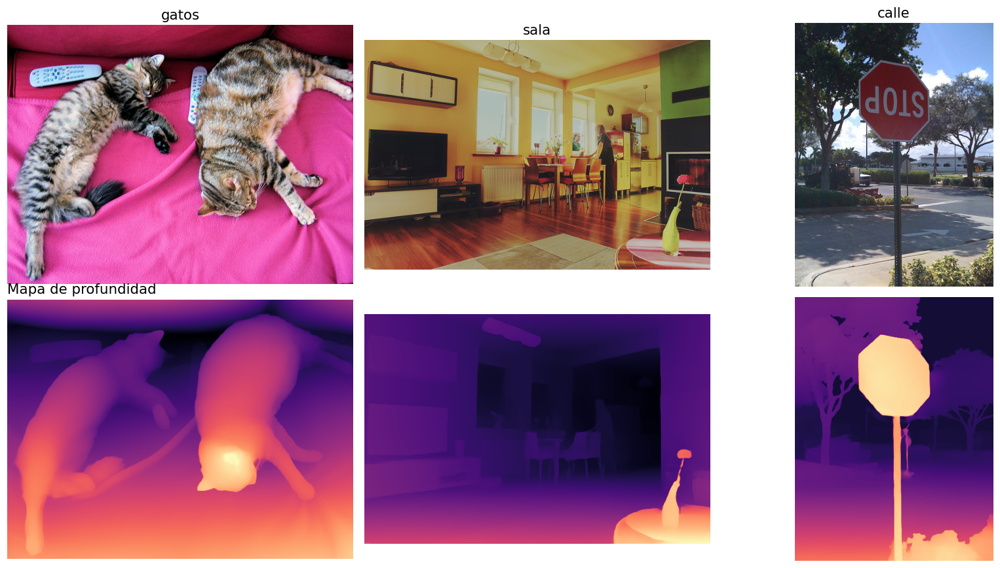

In [13]:
profundidad = pipeline("depth-estimation", model="depth-anything/Depth-Anything-V2-Small-hf", device=device)

# Adaptamos dinámicamente el número de columnas a la cantidad de imágenes que existan
num_columnas = len(imagenes)
fig, ejes = plt.subplots(2, num_columnas, figsize=(5 * num_columnas, 8))

# Nos aseguramos de que ejes sea bidimensional incluso con 1 sola imagen
if num_columnas == 1:
    ejes = ejes.reshape(2, 1)

for col, (nombre, im) in enumerate(imagenes.items()):
    mapa = profundidad(im)["depth"]
    ejes[0, col].imshow(im); ejes[0, col].axis("off"); ejes[0, col].set_title(nombre, fontsize=14)
    ejes[1, col].imshow(mapa, cmap="magma"); ejes[1, col].axis("off")
ejes[1, 0].set_title("Mapa de profundidad", fontsize=14, loc="left")
plt.tight_layout(); plt.show()

## 🎬 Remate: panel final 2x2
Original + detección + segmentación + profundidad, todo con una sola función. Ideal para grabar la pantalla.

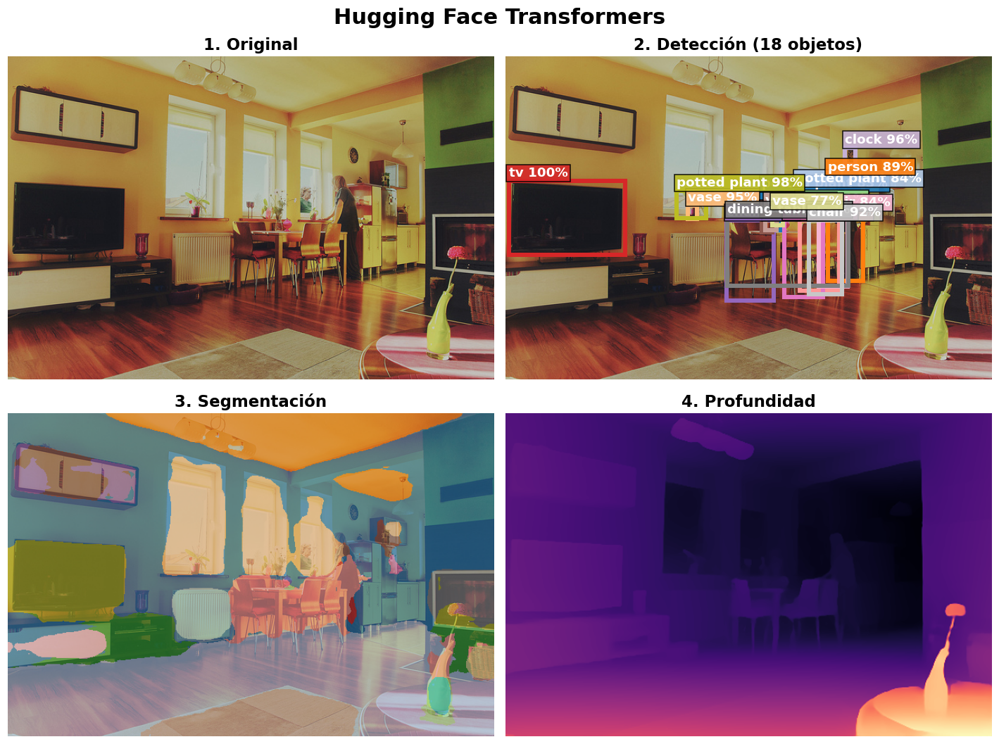

In [20]:
def panel_final(img, titulo="Hugging Face Transformers"):
    cajas = detector(img, threshold=0.7)
    segs = segmentador(img)
    seg_img, _ = superponer_segmentos(img, segs)
    mapa = profundidad(img)["depth"]

    fig, ejes = plt.subplots(2, 2, figsize=(13, 10))
    ejes[0, 0].imshow(img);                dibujar_cajas(ejes[0, 1], img, cajas)
    ejes[1, 0].imshow(seg_img);            ejes[1, 1].imshow(mapa, cmap="magma")
    ejes[0, 0].set_title("1. Original", fontsize=15, weight="bold")
    ejes[0, 1].set_title(f"2. Detección ({len(cajas)} objetos)", fontsize=15, weight="bold")
    ejes[1, 0].set_title("3. Segmentación", fontsize=15, weight="bold")
    ejes[1, 1].set_title("4. Profundidad", fontsize=15, weight="bold")
    for ax in ejes.ravel():
        ax.axis("off")
    fig.suptitle(titulo, fontsize=20, weight="bold")
    plt.tight_layout()
    plt.savefig("panel_final.png", dpi=200, bbox_inches="tight")
    plt.show()

panel_final(imagenes["sala"])
# Prueba también: panel_final(imagenes["gatos"]) o panel_final(imagenes["mi_foto"])

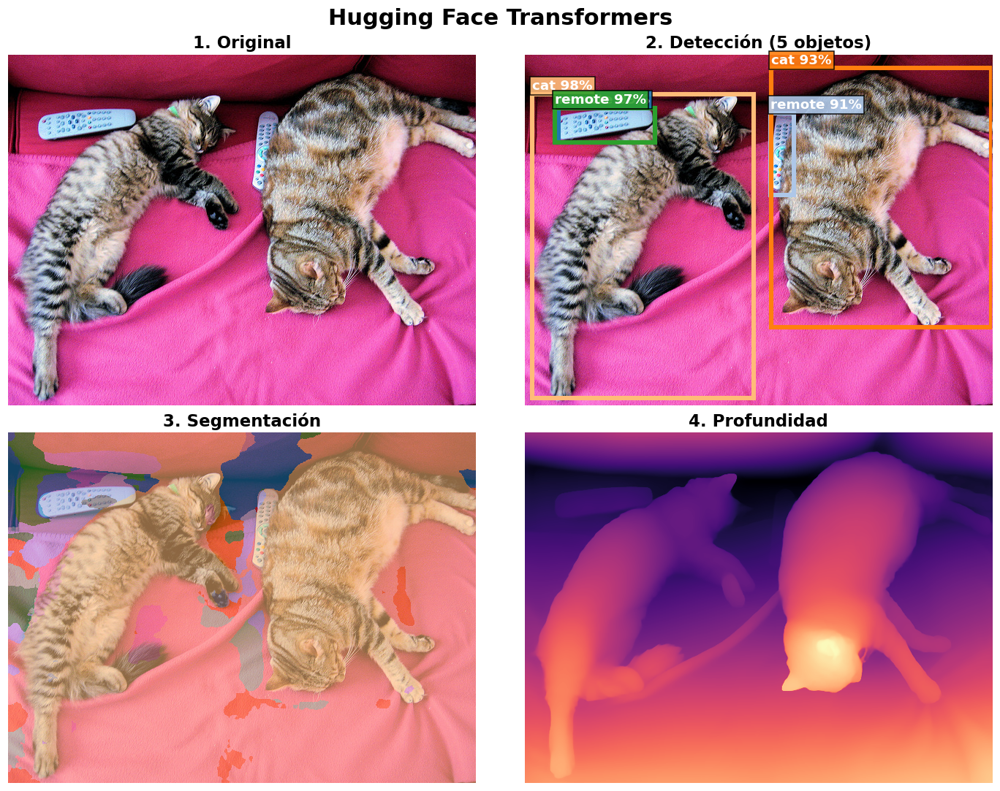

In [21]:
def panel_final(img, titulo="Hugging Face Transformers"):
    cajas = detector(img, threshold=0.7)
    segs = segmentador(img)
    seg_img, _ = superponer_segmentos(img, segs)
    mapa = profundidad(img)["depth"]

    fig, ejes = plt.subplots(2, 2, figsize=(13, 10))
    ejes[0, 0].imshow(img);                dibujar_cajas(ejes[0, 1], img, cajas)
    ejes[1, 0].imshow(seg_img);            ejes[1, 1].imshow(mapa, cmap="magma")
    ejes[0, 0].set_title("1. Original", fontsize=15, weight="bold")
    ejes[0, 1].set_title(f"2. Detección ({len(cajas)} objetos)", fontsize=15, weight="bold")
    ejes[1, 0].set_title("3. Segmentación", fontsize=15, weight="bold")
    ejes[1, 1].set_title("4. Profundidad", fontsize=15, weight="bold")
    for ax in ejes.ravel():
        ax.axis("off")
    fig.suptitle(titulo, fontsize=20, weight="bold")
    plt.tight_layout()
    plt.savefig("panel_final.png", dpi=200, bbox_inches="tight")
    plt.show()

panel_final(imagenes["gatos"])
# Prueba también: panel_final(imagenes["gatos"]) o panel_final(imagenes["mi_foto"])

## ✅ Resumen
| Tarea | `pipeline("...")` | Modelo |
|---|---|---|
| Sentimiento | `sentiment-analysis` | nlptown multilingüe |
| Texto | `text-generation` | Qwen2.5-0.5B-Instruct |
| Clasificación | `image-classification` | ViT |
| Zero-shot | `zero-shot-image-classification` | CLIP |
| Detección | `object-detection` | YOLOS-tiny |
| Segmentación | `image-segmentation` | SegFormer |
| Profundidad | `depth-estimation` | Depth Anything V2 |

📂 La imagen del panel se guardó como `panel_final.png` (panel izquierdo de Archivos en Colab).

👉 Sigue a **Laboratorio de Códigos** para más.